# Постановка задачи оптимального управления

$\dot{x} = f(x,u,t), \qquad  x \in \mathbb{R}^n, \qquad  u \in \mathbb{U}^m$

$x$ - вектор фазовых переменных, $u$ - вектор управляющих параметров.

Начальные и терминальные условия условия:

$$x(t_0) \in A = \left\{
    \begin{array}\\
       a_1(x,t) = 0 \\
        \dots \\
        a_l(x,t) = 0
    \end{array}   
\right. \qquad
x(t_f) \in B = \left\{
    \begin{array}\\
       b_1(x,t) = 0 \\
        \dots \\
        b_r(x,t) = 0
    \end{array}   
\right.$$


Функционал
$$\int_{t_0}^{t_f}I(x,u,t)dt + \Phi(x(t_f), t_f) \rightarrow \max_u$$

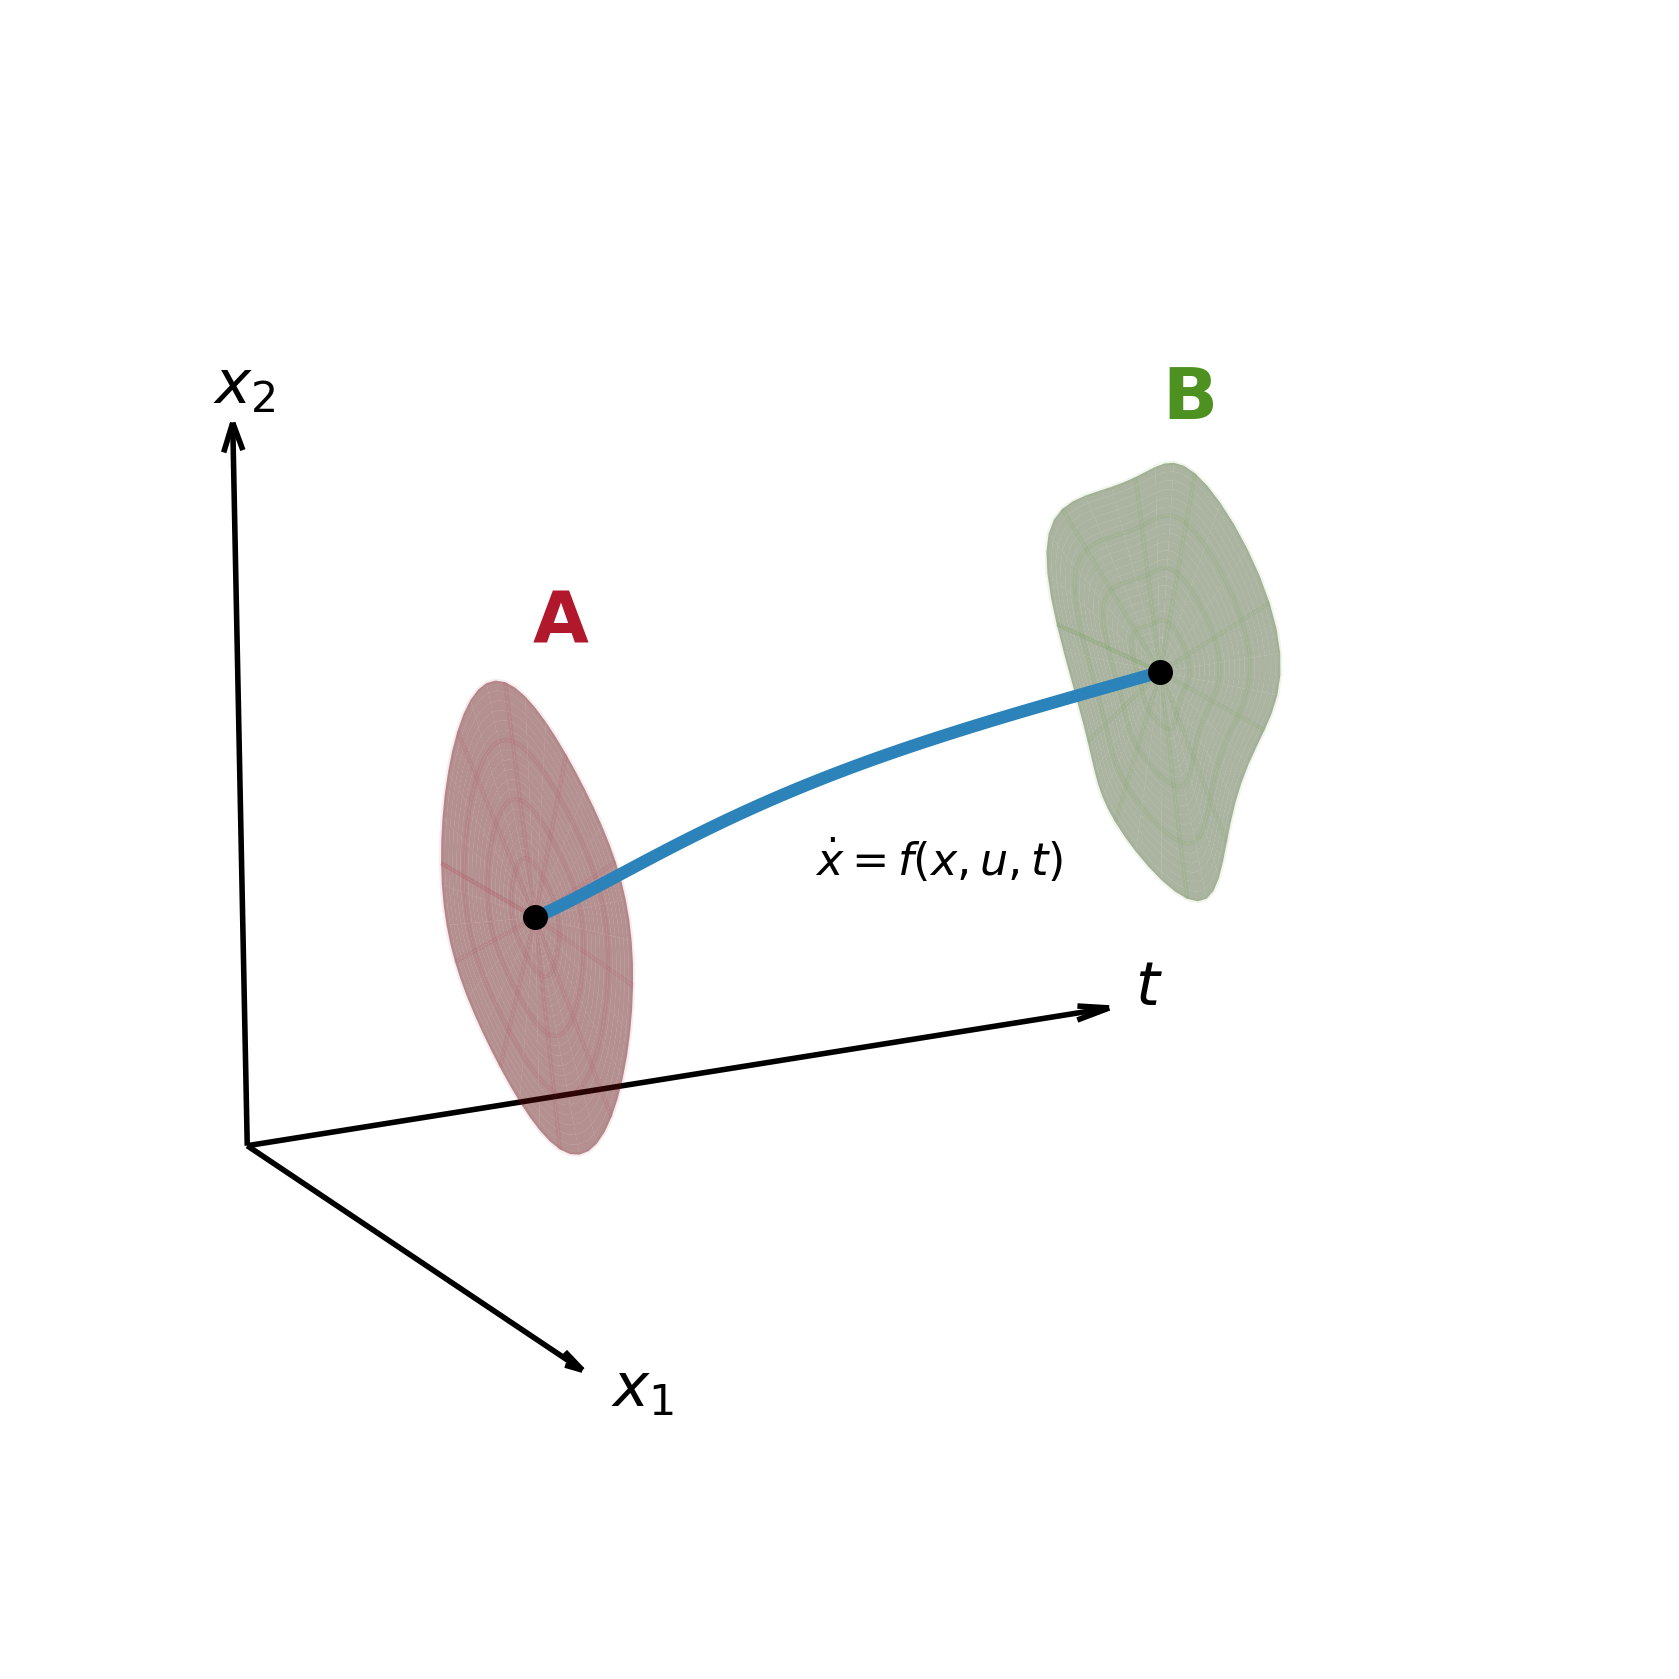

In [17]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

# Сброс стилей и включение высокого разрешения
plt.style.use('default')
%config InlineBackend.figure_format = 'retina'

fig = plt.figure(figsize=(11, 8.5))
ax = fig.add_subplot(111, projection='3d')

# --- Координаты ключевых центров и точек контакта ---
t0, tf = 1.2, 7.8  
x1_A_center, x2_A_center = -3.5, 4.2
x1_B_center, x2_B_center = -3.5, 6.2

# --- 1. Рисуем оси координат в виде стрелок ---
ax.quiver(0, 0, 0, 9.5, 0, 0, color='black', linewidth=2, arrow_length_ratio=0.04)
ax.quiver(0, 0, 0, 0, -6.5, 0, color='black', linewidth=2, arrow_length_ratio=0.05)
ax.quiver(0, 0, 0, 0, 0, 9.5, color='black', linewidth=2, arrow_length_ratio=0.04)

# Подписи осей
ax.text(9.8, 0, 0, '$t$', fontsize=22, weight='bold')
ax.text(0, -7.0, -0.2, '$x_1$', fontsize=22, weight='bold')
ax.text(-0.2, 0, 9.8, '$x_2$', fontsize=22, weight='bold')

# --- 2. Растянутые по вертикали многообразия A и B ---
r = np.linspace(0, 1.8, 25)
theta = np.linspace(0, 2*np.pi, 60)
R, THETA = np.meshgrid(r, theta)

# Многообразие A (растянуто по оси x2 множителем 1.5)
X1_A = x1_A_center + R * np.cos(THETA)
X2_A = x2_A_center + R * (1 + 0.15*np.sin(2*THETA)) * np.sin(THETA) * 1.5  
T_A = np.full_like(X1_A, t0)

ax.plot_surface(T_A, X1_A, X2_A, color='#d7191c', alpha=0.45, linewidth=0, antialiased=True)
ax.plot_wireframe(T_A, X1_A, X2_A, color='#b2182b', alpha=0.08, rstride=6, cstride=6)

# Многообразие B (растянуто по оси x2 множителем 1.5)
X1_B = x1_B_center + R * (1 + 0.2*np.sin(3*THETA)) * np.cos(THETA)
X2_B = x2_B_center + R * (1 + 0.1*np.cos(3*THETA)) * np.sin(THETA) * 1.5  
T_B = np.full_like(X1_B, tf)

ax.plot_surface(T_B, X1_B, X2_B, color='#a6d96a', alpha=0.45, linewidth=0, antialiased=True)
ax.plot_wireframe(T_B, X1_B, X2_B, color='#4d9221', alpha=0.08, rstride=6, cstride=6)

# --- 3. Траектория (строго соединяет центры черных точек) ---
t_grid = np.linspace(t0, tf, 100)
# Параболический закон без затухающих колебаний на финише, чтобы точно прийти в центр B
s = (t_grid - t0) / (tf - t0)
x1_traj = x1_A_center + (x1_B_center - x1_A_center) * s + 0.8 * np.sin(s * np.pi)
x2_traj = x2_A_center + (x2_B_center - x2_A_center) * (s ** 1.3)

# Синяя линия траектории
ax.plot(t_grid, x1_traj, x2_traj, color='#2b83ba', linewidth=4.5, zorder=10)

# Точки контакта на поверхностях (черные точки)
ax.plot([t0], [x1_A_center], [x2_A_center], marker='o', markersize=8, color='black', zorder=15)
ax.plot([tf], [x1_B_center], [x2_B_center], marker='o', markersize=8, color='black', zorder=15)

# --- 4. Подписи и формулы ---
ax.text(t0, x1_A_center, x2_A_center + 3.5, 'A', fontsize=26, color='#b2182b', weight='bold')
ax.text(tf, x1_B_center, x2_B_center + 3.3, 'B', fontsize=26, color='#4d9221', weight='bold')

# Уравнение смещено ближе к концу траектории и приподнято, чтобы не перекрываться кривой
ax.text(tf - 4.4, x1_B_center - 1.2, x2_B_center - 1.4, r'$\dot{x} = f(x, u, t)$', 
        fontsize=16, color='black', weight='bold', zorder=20)

# --- 5. Полное отключение стандартного куба и ракурс ---
ax.set_axis_off()
ax.view_init(elev=16, azim=-118)

# Границы невидимого куба
ax.set_xlim(0, 9.5)
ax.set_ylim(-7.5, 1)
ax.set_zlim(0, 9.5)

plt.tight_layout()
plt.show()


# Принцип оптимальности

Оптимальное поведение системы обладает тем свойством, что каковы бы ни были начальное состояние системы и принятое начальное решение (то есть управление), последующие решения должны составлять оптимальное поведение относительно состояния, получающегося в результате первоначального поведения.

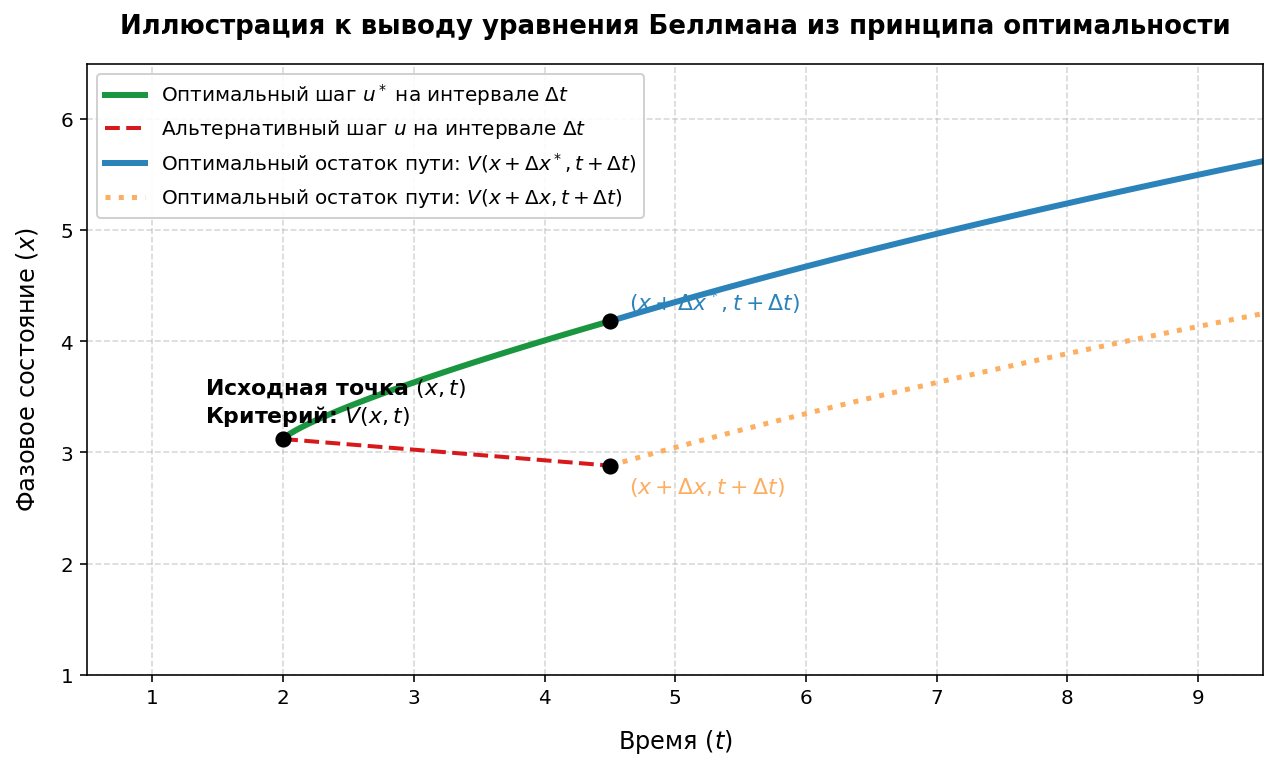

In [8]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

# Настройка качественного отображения графиков в Jupyter
%config InlineBackend.figure_format = 'retina' 

# Создаем подложку графика
fig, ax = plt.subplots(figsize=(9, 5.5))

# Генерируем данные для гладких кривых
t = np.linspace(0, 10, 100)
x_opt_full = 1 + np.sqrt(t) * 1.5  # Идеальный теоретический путь

# Ключевые временные точки
t0, t1 = 2, 4.5
x0 = 1 + np.sqrt(t0) * 1.5
x1_opt = 1 + np.sqrt(t1) * 1.5
x1_alt = x1_opt - 1.3

# 1. Отрезок времени dt (шаг управления)
t_dt = np.linspace(t0, t1, 50)
# Оптимальный шаг u*
ax.plot(t_dt, x0 + (x1_opt - x0)*((t_dt - t0)/(t1 - t0))**0.8, 
        color='#1a9641', linewidth=3, label='Оптимальный шаг $u^*$ на интервале $\\Delta t$')
# Альтернативный шаг u
ax.plot(t_dt, x0 + (x1_alt - x0)*(t_dt - t0)/(t1 - t0), 
        color='#d7191c', linestyle='--', linewidth=2, label='Альтернативный шаг $u$ на интервале $\\Delta t$')

# 2. Оптимальное продолжение (после момента t + dt)
t_rest = np.linspace(t1, 10, 50)
# Продолжение для оптимальной ветки
ax.plot(t_rest, 1 + np.sqrt(t_rest) * 1.5, 
        color='#2b83ba', linewidth=3, label='Оптимальный остаток пути: $V(x + \\Delta x^*, t + \\Delta t)$')
# Продолжение для альтернативной ветки (тоже оптимальное согласно принципу Беллмана)
x_alt_rest = x1_alt + (1 + np.sqrt(t_rest)*1.5 - x1_opt) * 0.95
ax.plot(t_rest, x_alt_rest, 
        color='#fdae61', linestyle=':', linewidth=2.5, label='Оптимальный остаток пути: $V(x + \\Delta x, t + \\Delta t)$')

# Обозначение узловых точек (состояний)
ax.scatter([t0, t1, t1], [x0, x1_opt, x1_alt], color='black', s=50, zorder=5)

# Текстовые подписи к точкам (с поддержкой LaTeX)
ax.text(t0 - 0.6, x0 + 0.15, r'Исходная точка $(x, t)$' + '\n' + r'Критерий: $V(x,t)$', fontsize=11, fontweight='bold')
ax.text(t1 + 0.15, x1_opt + 0.1, r'$(x + \Delta x^*, t + \Delta t)$', fontsize=11, color='#2b83ba', weight='bold')
ax.text(t1 + 0.15, x1_alt - 0.25, r'$(x + \Delta x, t + \Delta t)$', fontsize=11, color='#fdae61', weight='bold')

# Оформление осей и сетки
ax.set_xlabel('Время ($t$)', fontsize=12, labelpad=10)
ax.set_ylabel('Фазовое состояние ($x$)', fontsize=12, labelpad=10)
ax.set_title('Иллюстрация к выводу уравнения Беллмана из принципа оптимальности', fontsize=13, pad=15, weight='bold')

ax.set_xlim(0.5, 9.5)
ax.set_ylim(1, 6.5)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper left', fontsize=10, framealpha=0.9)

plt.tight_layout()
plt.show()


from IPython.display import HTML

# Этот скрипт создает кнопку, которая прячет/показывает код текущей ячейки
HTML('''<script>
code_show=true; 
function code_toggle() {
 if (code_show){
 $('div.input').hide();
 } else {
 $('div.input').show();
 }
 code_show = !code_show
} 
$( document ).ready(code_toggle);
</script>
<form action="javascript:code_toggle()"><input type="submit" value="Нажмите, чтобы показать/скрыть код этой ячейки."></form>''')


## Уравнение Беллмана
Максимальное значение критерия качества для системы, находящейся в состоянии $x$ в момент времени $t$, определяется как опорная функция $V(x, t)$:
$$J^* = V(x,t) \tag{1}$$

Согласно принципу оптимальности, значение $V(\xi + d\xi, \tau + d\tau)$ соответствует значению опорной функции для измененных начальных условий $(\xi + d\xi, \tau + d\tau)$, расположенных на той же экстремальной траектории, что и исходная точка $(\xi, \tau)$. Приращение опорной функции вдоль оптимальной траектории за промежуток времени $\Delta t$ обусловлено исключительно изменением интегральной части критерия. Справедливо рекуррентное соотношение:
$$V(x,t) = \max_{u \in \mathbb{U}^m} \Big( I(x,u,t)\Delta t + V(x+\Delta x, t + \Delta t) \Big) \tag{2}$$

Максимизация в соотношении (2) выполняется по множеству допустимых мгновенных значений управления $\mathbb{U}^m$ в текущий момент времени.

При условии непрерывной дифференцируемости функции $V(x,t)$ разложение в ряд Тейлора в окрестности точки $(x, t)$ имеет вид:
$$V(x+\Delta x, t+\Delta t) = V(x,t) + \frac{\partial V}{\partial x}\Delta x + \frac{\partial V}{\partial t}\Delta t + o(\Delta t) \tag{3}$$

где $\frac{\partial V}{\partial x} = \left( \frac{\partial V}{\partial x_1}, \dots, \frac{\partial V}{\partial x_n} \right)$ - вектор-строка частных производных по фазовому вектору.

*Замечание о гладкости:* Непрерывная дифференцируемость опорной функции гарантирована не во всех классах задач. В точках излома производных уравнение Беллмана понимается в обобщенном смысле (в рамках теории вязкостных решений).

Подстановка (3) в (2) дает:
$$V(x,t) = \max_{u \in \mathbb{U}^m} \left[ I(x,u,t)\Delta t + V(x,t) + \frac{\partial V}{\partial x}\Delta x + \frac{\partial V}{\partial t}\Delta t + o(\Delta t) \right] \tag{4}$$

Члены $V(x,t)$ и $\frac{\partial V}{\partial t}\Delta t$ не зависят от управления $u$. После их вынесения за знак максимизации и сокращения $V(x,t)$ в обеих частях равенства выражение принимает вид:
$$0 = \frac{\partial V}{\partial t}\Delta t + \max_{u \in \mathbb{U}^m} \left[ I(x,u,t)\Delta t + \frac{\partial V}{\partial x}\Delta x \right] + o(\Delta t) \tag{5}$$

Деление уравнения (5) на $\Delta t > 0$ дает:
$$0 = \frac{\partial V}{\partial t} + \max_{u \in \mathbb{U}^m} \left[ I(x,u,t) + \frac{\partial V}{\partial x} \frac{\Delta x}{\Delta t} \right] + \frac{o(\Delta t)}{\Delta t} \tag{6}$$

Предельный переход при $\Delta t \to 0$ с учетом дифференциальной связи $\dot{x} = \lim_{\Delta t \to 0} \frac{\Delta x}{\Delta t} = f(x,u,t)$ определяет непрерывную форму уравнения:
$$\frac{\partial V}{\partial t} + \max_{u \in \mathbb{U}^m} \left[ I(x,u,t) + \frac{\partial V}{\partial x} \cdot f(x,u,t) \right] = 0 \tag{7}$$

Уравнение (7) с граничным условием на правом конце (терминальным условием):
$$V(x(t_f), t_f) = \Phi(x(t_f), t_f) \tag{8}$$

где $\Phi(x(t_f), t_f)$ - терминальный функционал, называется уравнением Беллмана (или уравнением Гамильтона-Якоби-Беллмана).

## Комментарии к структуре уравнения
1. **Операция максимизации**: Выполняется локально по вектору управлений $u$ для каждого фиксированного момента времени $t$ и состояния $x$. Это сводит вариационную задачу нахождения оптимальной функции времени $u^*(t)$ к задаче математического программирования в пространстве $\mathbb{R}^m$.
2. **Скалярное произведение**: Слагаемое $\frac{\partial V}{\partial x} \cdot f(x,u,t)$ является полной производной опорной функции по времени вдоль траектории системы, обусловленной изменением пространственных координат.
3. **Краевое условие**: Уравнение интегрируется в обратном временном направлении от момента $t_f$ к $t_0$, так как условие (8) задано на правом конце траектории.


# Достаточные условия оптимальности

**Теорема.** Если существуют непрерывно дифференцируемая опорная функция $V(x,t)$ и допустимое управление $u^*(t)$ с соответствующей траекторией $x^*(t)$, удовлетворяющие на интервале $[t_0, t_f]$ условиям:

1. Уравнению Беллмана в каждой точке фазового пространства:
$$\frac{\partial V(x,t)}{\partial t} + \max_{u \in \mathbb{U}^m} \left[ I(x,u,t) + \frac{\partial V(x,t)}{\partial x} \cdot f(x,u,t) \right] = 0$$

2. Условию максимума на оптимальной траектории:
$$I(x^*(t), u^*(t), t) + \frac{\partial V(x^*(t),t)}{\partial x} \cdot f(x^*(t), u^*(t), t) = \max_{u \in \mathbb{U}^m} \left[ I(x^*(t), u, t) + \frac{\partial V(x^*(t),t)}{\partial x} \cdot f(x^*(t), u, t) \right]$$

3. Граничному условию на правом конце:
$$V(x^*(t_f), t_f) = \Phi(x^*(t_f), t_f)$$

то управление $u^*(t)$ является оптимальным, а $x^*(t)$ - оптимальной траекторией.

### Схема построения синтеза оптимального управления

1. Из уравнения Беллмана определяется функция безусловного максимума по управлению (закон синтеза):
$$v(x,t) = \arg\max_{u \in \mathbb{U}^m} \left[ I(x,u,t) + \frac{\partial V(x,t)}{\partial x} \cdot f(x,u,t) \right]$$

2. Функция $v(x,t)$ подставляется в уравнение Беллмана, формируя нелинейное дифференциальное уравнение в частных производных относительно неизвестной опорной функции $V(x,t)$:
$$\frac{\partial V(x,t)}{\partial t} + I(x, v(x,t), t) + \frac{\partial V(x,t)}{\partial x} \cdot f(x, v(x,t), t) = 0$$

3. Решается полученное уравнение в частных производных с терминальным условием $V(x(t_f), t_f) = \Phi(x(t_f), t_f)$ для нахождения явного вида $V(x,t)$.

4. Оптимальная траектория $x^*(t)$ находится как решение задачи Коши для системы обыкновенных дифференциальных уравнений:
$$\begin{cases} 
\dot{x}^*(t) = f(x^*(t), v(x^*(t), t), t) \\ 
x^*(t_0) = x_0 
\end{cases}$$

5. Оптимальное программное управление вычисляется вдоль найденной траектории:
$$u^*(t) = v(x^*(t), t)$$


# Пример. Синтез управления материальной точкой

Рассматривается задача управления движением материальной точки по прямой под действием управляющей силы $u$. Система уравнений в пространстве состояний имеет вид:
$$\begin{cases}
\dot{x} = v \\
\dot{v} = u
\end{cases}$$

где $x$ - координата, $v$ - скорость, $u \in \mathbb{R}$ - управление.

Максимизируемый функционал задан в виде:
$$J = - \int_{0}^{\infty} (x^2 + u^2) dt \rightarrow \max_u$$

Граничные условия:
$$x(0) = x_0, \qquad v(0) = v_0, \qquad \lim_{t \to \infty} x(t) = 0$$

Рассматривается задача на **бесконечном горизонте прогнозирования** ($t_f = \infty$), при этом терминальный функционал отсутствует ($\Phi \equiv 0$). Поскольку подынтегральное выражение и уравнения динамики не зависят от времени явным образом, ищется стационарная опорная функция $V(x, v)$, для которой $\frac{\partial V}{\partial t} = 0$. Условие на бесконечности принимает вид $V(0, 0) = 0$.

Уравнение Беллмана для данной системы:
$$\max_{u} \left[ -(x^2 + u^2) + \frac{\partial V}{\partial x}v + \frac{\partial V}{\partial v}u \right] = 0 \tag{1}$$

Для нахождения максимума подынтегральное выражение дифференцируется по переменной $u$:
$$-2u + \frac{\partial V}{\partial v} = 0 \implies u^* = \frac{1}{2}\frac{\partial V}{\partial v} \tag{2}$$

Подставим оптимальное управление (2) обратно в уравнение (1). Заметим, что комбинация членов с управлением дает:
$$-(u^*)^2 + \frac{\partial V}{\partial v}u^* = -\frac{1}{4}\left(\frac{\partial V}{\partial v}\right)^2 + \frac{1}{2}\left(\frac{\partial V}{\partial v}\right)^2 = +\frac{1}{4}\left(\frac{\partial V}{\partial v}\right)^2$$

В результате получаем нелинейное уравнение в частных производных:
$$-x^2 + \frac{1}{4}\left(\frac{\partial V}{\partial v}\right)^2 + \frac{\partial V}{\partial x}v = 0 \tag{3}$$

Решение уравнения (3) ищется в форме отрицательно определенной квадратичной формы:
$$V(x, v) = ax^2 + 2bxv + cv^2 \tag{4}$$

Частные производные функции (4):
$$\frac{\partial V}{\partial x} = 2ax + 2bv, \qquad \frac{\partial V}{\partial v} = 2bx + 2cv \tag{5}$$

Подстановка производных (5) в уравнение (3):
$$-x^2 + \frac{1}{4}(2bx + 2cv)^2 + (2ax + 2bv)v = 0$$
$$-x^2 + (bx + cv)^2 + 2axv + 2bv^2 = 0$$
$$-x^2 + b^2x^2 + 2bcxv + c^2v^2 + 2axv + 2bv^2 = 0$$

Группировка слагаемых при одинаковых степенях переменных:
$$x^2(b^2 - 1) + xv(2bc + 2a) + v^2(c^2 + 2b) = 0 \tag{6}$$

Равенство (6) выполняется тождественно при нулевых значениях коэффициентов:
1. $b^2 - 1 = 0 \implies b = \pm 1$. Из условия асимптотической устойчивости замкнутой системы выбирается $b = -1$.
2. $c^2 + 2b = 0 \implies c^2 - 2 = 0 \implies c = \pm\sqrt{2}$. Из условия отрицательной определенности квадратичной формы выбирается $c = -\sqrt{2}$.
3. $2bc + 2a = 0 \implies a = -bc = -(-1)(-\sqrt{2}) = -\sqrt{2}$.

Явный вид опорной функции:
$$V(x, v) = -\sqrt{2}x^2 - 2xv - \sqrt{2}v^2 \tag{7}$$

Согласно соотношению (2), закон оптимального синтеза управления определяется как:
$$u^*(x, v) = bx + cv = -x - \sqrt{2}v \tag{8}$$


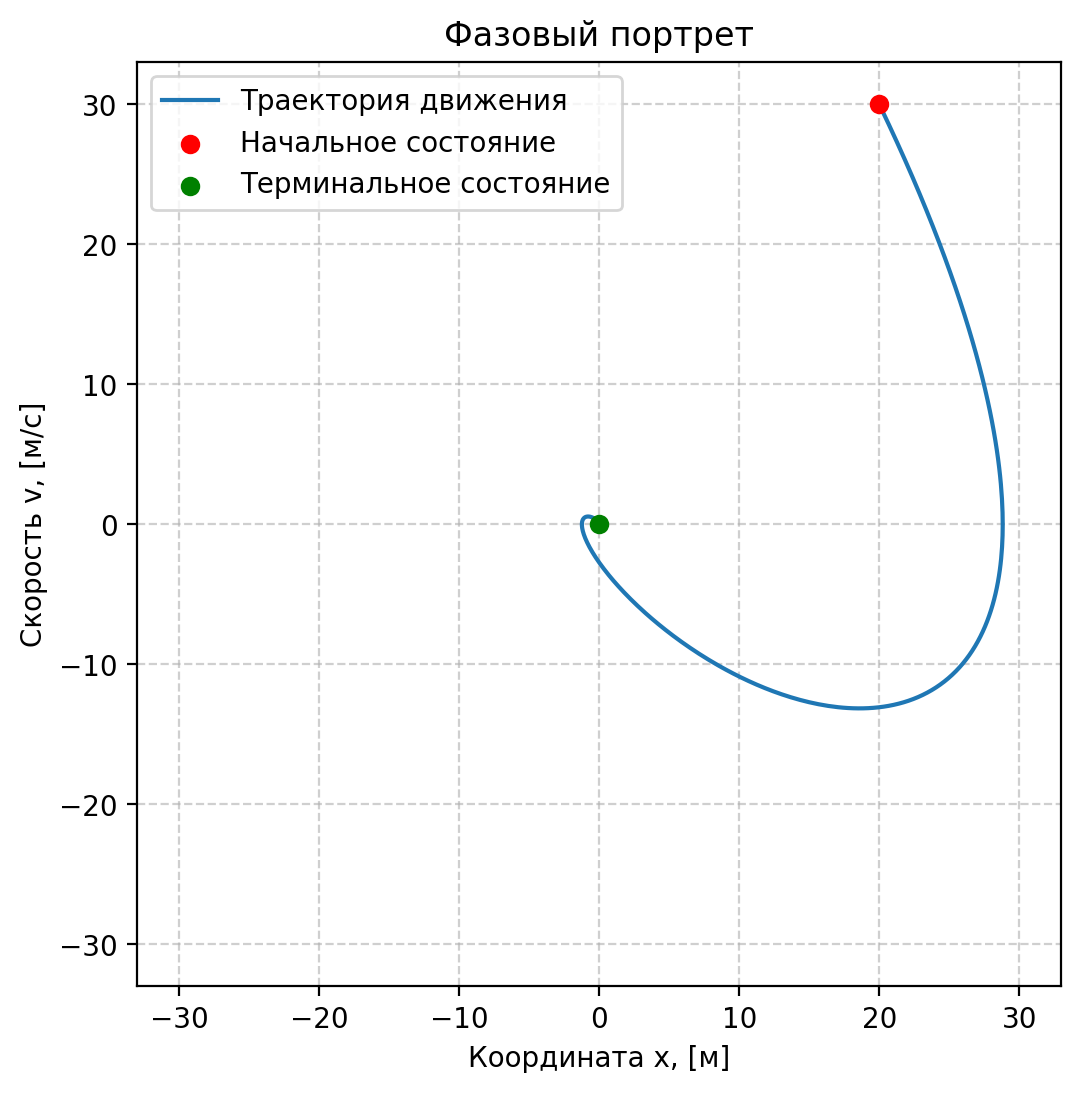

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

def u_optimal(x, v):
    """Закон оптимального синтеза управления."""
    return -x - np.sqrt(2) * v

def system_dynamics(t, state):
    """Дифференциальные уравнения замкнутой системы."""
    x, v = state
    u = u_optimal(x, v)
    return [v, u]

def terminal_event(t, state):
    """Функция фиксации достижения терминального состояния x = 0."""
    return state[0]

# Настройка параметров интегратора
terminal_event.terminal = True
terminal_event.direction = None

# Начальные условия
x0 = 20.0
v0 = 30.0
t_span = (0.0, 100.0)  # Достаточный временной интервал

# Численное интегрирование задачи Коши
solution = solve_ivp(
    system_dynamics,
    t_span,
    [x0, v0],
    events=terminal_event,
    atol=1e-11,
    rtol=1e-11
)

# Визуализация фазовой траектории
phase_trajectory = solution.y.T
limit_val = max(abs(x0), abs(v0)) * 1.1

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(phase_trajectory[:, 0], phase_trajectory[:, 1], label="Траектория движения")
ax.scatter([x0], [v0], color="red", zorder=5, label="Начальное состояние")
ax.scatter([phase_trajectory[-1, 0]], [phase_trajectory[-1, 1]], color="green", zorder=5, label="Терминальное состояние")

ax.set_xlim(-limit_val, limit_val)
ax.set_ylim(-limit_val, limit_val)
ax.grid(True, linestyle="--", alpha=0.6)
ax.set_title("Фазовый портрет")
ax.set_xlabel("Координата x, [м]")
ax.set_ylabel("Скорость v, [м/с]")
ax.set_aspect("equal")
ax.legend()
plt.show()


# Пример 2. Задача о мягкой посадке космического аппарата

Рассматривается задача вертикального торможения космического аппарата в однородном гравитационном поле при отсутствии атмосферы (задача о мягкой посадке). Целью является перевод аппарата на поверхность планеты с нулевой финальной скоростью при минимальном расходе топлива.

Динамика управляемого объекта описывается системой нелинейных дифференциальных уравнений:
$$\begin{cases}
\dot{h} = v \\
\dot{v} = \frac{u}{m} - g \\
\dot{m} = -\gamma u
\end{cases}$$

где $h$ - высота ($h \geq 0$), $v$ - вертикальная скорость, $m$ - текущая масса аппарата, $g$ - ускорение свободного падения, $\gamma$ - коэффициент расхода массы, $u$ - тяга двигателя, являющаяся управляющим воздействием.

На управление наложено жесткое ограничение типа неравенства:
$$0 \leq u \leq U_{\max}$$

Граничные условия задачи:
$$h(0) = h_0, \qquad v(0) = v_0, \qquad m(0) = m_0$$
$$h(t_f) = 0, \qquad v(t_f) = 0, \qquad m(t_f) \rightarrow \max$$

Минимизация расхода топлива эквивалентна максимизации конечной массы, что позволяет записать критерий качества в виде максимизации терминального функционала (задача Майера):
$$J = m(t_f) \rightarrow \max_u$$

### Составление уравнения Беллмана

Поскольку система автономна, стационарная опорная функция зависит от трех фазовых переменных: $V = V(h, v, m)$. Терминальное условие имеет вид:
$$V(0, 0, m) = m$$

Уравнение Беллмана для непрерывной нелинейной системы принимает форму:
$$\max_{0 \leq u \leq U_{\max}} \left[ \frac{\partial V}{\partial h}v + \frac{\partial V}{\partial v}\left(\frac{u}{m} - g\right) - \frac{\partial V}{\partial m}\gamma u \right] = 0 \tag{1}$$

Группируя слагаемые при управляющем воздействии $u$, получаем:
$$\frac{\partial V}{\partial h}v - g\frac{\partial V}{\partial v} + \max_{0 \leq u \leq U_{\max}} \left[ u \cdot \left( \frac{1}{m}\frac{\partial V}{\partial v} - \gamma \frac{\partial V}{\partial m} \right) \right] = 0 \tag{2}$$

Определим переключающую функцию $\psi(h, v, m)$:
$$\psi(h, v, m) = \frac{1}{m}\frac{\partial V}{\partial v} - \gamma \frac{\partial V}{\partial m} \tag{3}$$

Поскольку выражение (2) линейно по управлению $u$, максимум достигается на границе области допустимых значений в зависимости от знака функции переключения (релейное управление):
$$u^* = \begin{cases} 
U_{\max}, & \text{если } \psi(h, v, m) > 0 \\ 
0, & \text{если } \psi(h, v, m) < 0 
\end{cases} \tag{4}$$

### Синтез оптимальной траектории методом обратного интегрирования

Поиск точного аналитического решения уравнения в частных производных (2) сопряжен с высокими математическими трудностями из-за нелинейности по массе. Практический синтез управления строится на основе интегрирования уравнений динамики в обратном времени от терминального состояния $(h=0, v=0)$ при максимальной тяге $u = U_{\max}$ (этап активного торможения непосредственно перед посадкой).

Обозначим обратное время как $\tau = t_f - t$. Динамика системы в обратном времени при $u = U_{\max}$ принимает вид:
$$\begin{cases}
\frac{dh}{d\tau} = -v \\
\frac{dv}{d\tau} = g - \frac{U_{\max}}{m} \\
\frac{dm}{d\tau} = \gamma U_{\max}
\end{cases}$$

Интегрирование данной системы с конца позволяет получить аналитические зависимости фазовых координат, задающие **линию переключения** на фазовой плоскости $(h, v)$. Управление переключается с $u=0$ (свободное падение) на $u=U_{\max}$ (максимальная тяга) в момент пересечения фазовой траектории с этой линией.


## Вычислительные методы и особенности программной реализации

Численное решение непрерывных уравнений Беллмана для нелинейных систем связано с рядом вычислительных задач: аппроксимацией разрывных (релейных) управлений, обеспечением точности срабатывания условий останова и минимизацией погрешности дискретизации. Для обеспечения сходимости траектории к терминальному состоянию с заданной точностью в разработанном алгоритме применен комплекс из четырех вычислительных методов.

### 1. Метод интегрирования в обратном времени для построения линии переключения
Прямой аналитический синтез функции переключения $\psi(h, v, m)$ в фазовом пространстве затруднен вследствие нелинейности уравнений динамики по массе (слагаемое $\frac{u}{m}$). Для обхода данной трудности используется замена переменной времени на обратное: $\tau = t_f - t$.
* Исходными данными для интегрирования назад по времени служат точные терминальные значения состояния системы: $h(0)=0, v(0)=0$ при максимальном значении управляющего воздействия $u = U_{\max}$.
* В результате интегрирования формируются массивы координат `h_switch_line` и `v_switch_line`, определяющие геометрию стационарной линии переключения в фазовом пространстве.

### 2. Динамический поиск точки пересечения фазовых траекторий
Стандартные процедуры поиска событий (Event Location) в численных методах интегрирования обыкновенных дифференциальных уравнений (ОДУ) могут приводить к потере точности при пересечении разрывных границ управления, если величина шага интегрирования сопоставима с характерным масштабом изменения фазовых координат.
* Для повышения точности пассивный полет (Фаза А) интегрируется на плотной дискретной сетке времени.
* На каждом шаге вычисляется расстояние по пространственной координате до линии переключения. Момент переключения фиксируется, когда текущая скорость системы $v_{\text{curr}}$ становится меньше или равна критическому значению скорости торможения $v_{\text{bellman}}(h)$, определенному на Линии Беллмана для данной высоты. В этот момент интегрирование Фазы А прекращается, а конечный вектор состояния передается в качестве начальных условий для Фазы Б.

### 3. Метод стрельбы (пристрелки) по граничным условиям
При интегрировании в обратном времени значение массы аппарата в терминальный момент времени ($m_{\text{final}}$) задается априорно в качестве варьируемого параметра. Отклонение данного параметра от истинного значения приводит к несоответствию располагаемой тяги двигателя реальной массе системы при прямом моделировании. В результате скорость системы обращается в ноль до достижения геометрической границы $h=0$.
* Для обеспечения одновременного выполнения граничных условий по высоте и скорости сформулирована одномерная задача оптимизации, решаемая с помощью функции `scipy.optimize.root_scalar`.
* Алгоритм осуществляет поиск корня функции ошибки $e(m_{\text{final}}) = h_{\text{stop}}$, итерационно корректируя значение терминальной массы до достижения сходимости по конечной высоте с точностью не хуже $10^{-5}$ метра.

### 4. Двухкритериальное условие останова интегрирования
При численном моделировании фазы активного торможения (Фаза Б) накопленная погрешность интегратора ОДУ может приводить к смене знака скорости (перерегулированию) до фиксации момента приземления, что вызывает физически некорректное изменение направления движения системы.
* Реализованная функция условия останова `landed_or_hover_event` осуществляет непрерывный мониторинг двух критериев окончания процесса: достижения нулевой отметки по высоте ($h \leq 0$) либо достижения нулевого значения вертикальной скорости ($v \geq 0$). Данный подход гарантирует корректное завершение вычислений в точке остановки фазовой траектории.


Запуск автоматического метода пристрелки Беллмана...
Оптимальная масса на поверхности найдена: 6.05078 кг


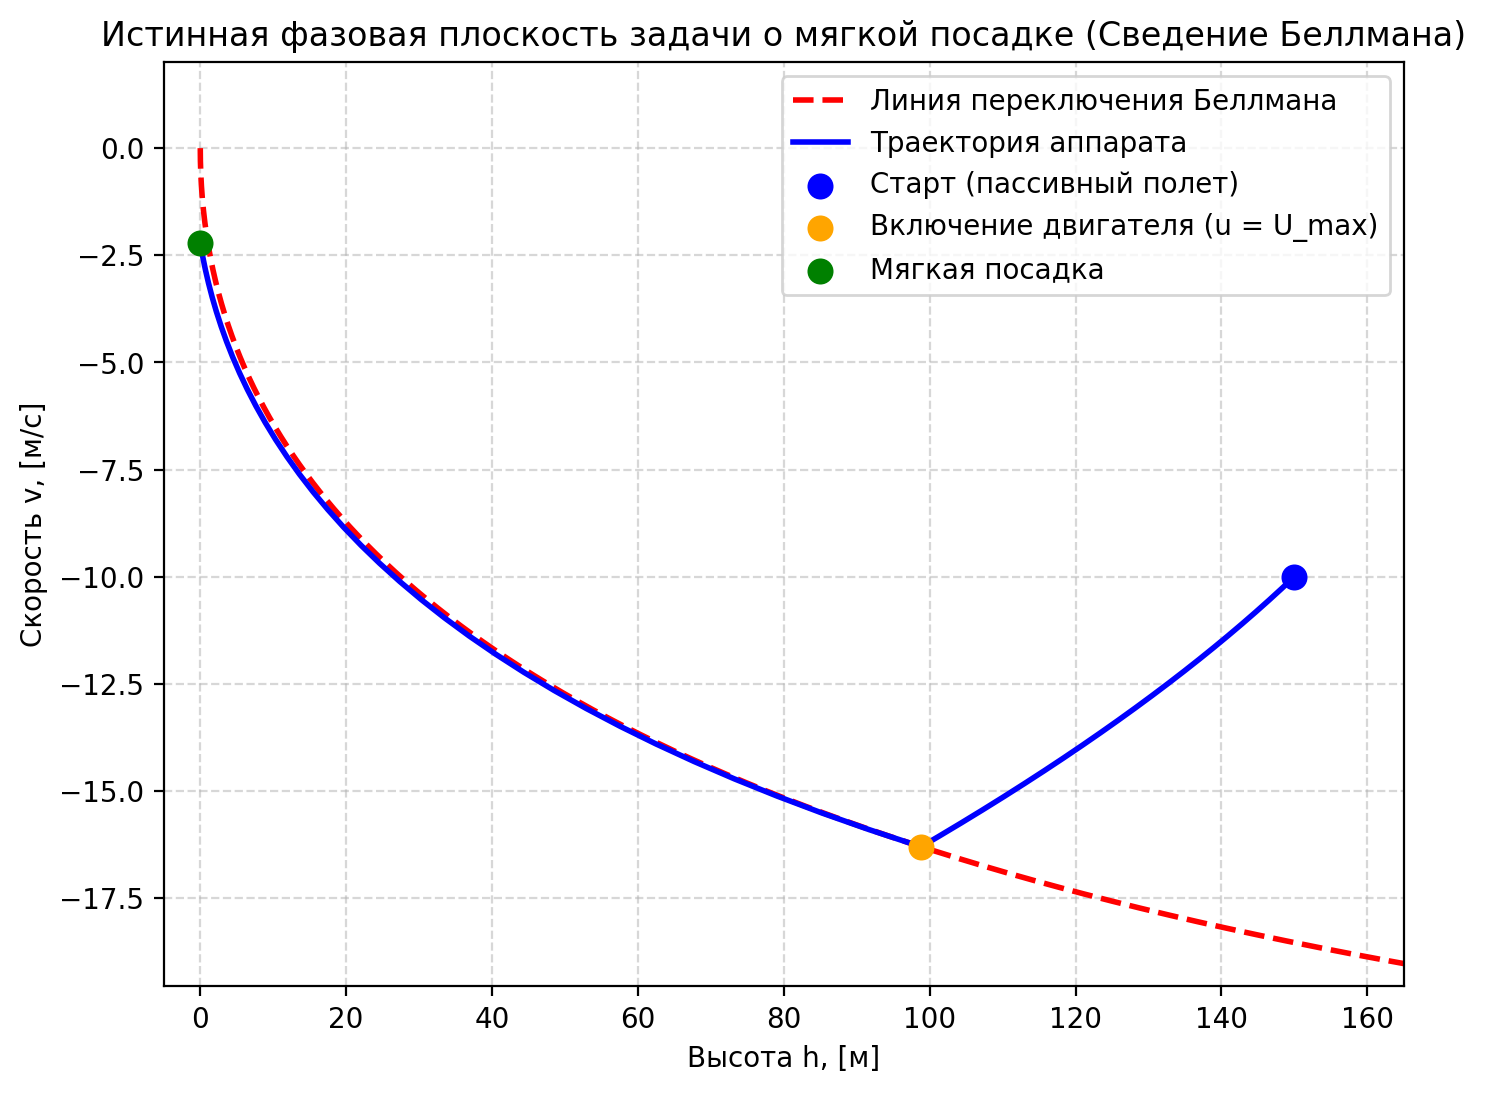

Финальная высота: 0.00000 м
Скорость касания поверхности: -2.212746 м/с
Остаток массы: 6.42 кг (расход топлива: 3.58 кг)


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar

# Физические параметры системы (в условных единицах)
G_ACCEL = 1.62       # Ускорение свободного падения (Луна)
GAMMA = 0.015       # Коэффициент расхода массы
U_MAX = 25.0        # Максимальная тяга двигателя

# Начальные условия
h0 = 150.0   # Начальная высота, [м]
v0 = -10.0   # Начальная скорость, [м/с] (движение вниз)
m0 = 10.0    # Начальная масса, [кг]

def simulate_landing(m_final_guess):
    """
    Полный цикл симуляции для заданной предполагаемой финальной массы.
    Возвращает конечную высоту аппарата при гашении скорости.
    """
    # ЭТАП 1: Расчет линии переключения
    def backward_dynamics(tau, state):
        h, v, m = state
        return [v, U_MAX / m - G_ACCEL, GAMMA * U_MAX]

    sol_backward = solve_ivp(
        backward_dynamics, 
        (0.0, 40.0), 
        [0.0, 0.0, m_final_guess], 
        t_eval=np.linspace(0, 40, 2000), 
        atol=1e-10, rtol=1e-10
    )
    
    h_switch_line = sol_backward.y[0, :]
    v_switch_line = -sol_backward.y[1, :]

    # ЭТАП 2: Прямое моделирование пассивного полета (Фаза А)
    def passive_dynamics(t, state):
        h, v, m = state
        return [v, -G_ACCEL, 0.0]

    sol_phase_A = solve_ivp(
        passive_dynamics, 
        (0.0, 50.0), 
        [h0, v0, m0], 
        t_eval=np.linspace(0, 50, 5000),
        atol=1e-10, rtol=1e-10
    )

    idx_switch = None
    for i in range(sol_phase_A.y.shape[1]):
        h_curr = sol_phase_A.y[0, i]
        v_curr = sol_phase_A.y[1, i]
        if h_curr <= 0: 
            break
        closest_idx = np.argmin(np.abs(h_switch_line - h_curr))
        v_bellman = v_switch_line[closest_idx]
        if v_curr <= v_bellman:
            idx_switch = i
            break

    if idx_switch is None:
        return 999.0 # Траектории не пересеклись
        
    t_switch = sol_phase_A.t[idx_switch]
    state_switch = sol_phase_A.y[:, idx_switch]
    
    # ЭТАП 3: Активное торможение (Фаза Б)
    def active_dynamics(t, state):
        h, v, m = state
        return [v, U_MAX / m - G_ACCEL, -GAMMA * U_MAX]

    def landed_or_hover_event(t, state):
        h, v, m = state
        if v >= -1e-4: 
            return 0.0  # Зависание / остановка по скорости
        return h        # Касание земли

    landed_or_hover_event.terminal = True
    landed_or_hover_event.direction = -1

    sol_phase_B = solve_ivp(
        active_dynamics, 
        (t_switch, t_switch + 20.0), 
        state_switch, 
        events=landed_or_hover_event,
        atol=1e-11, rtol=1e-11
    )
    
    # Возвращаем конечную высоту и полные результаты для финального рендера
    h_final = sol_phase_B.y[0, -1]
    return h_final, (sol_phase_A, sol_phase_B, idx_switch, h_switch_line, v_switch_line, state_switch)

# -----------------------------------------------------------------------------
# АВТОМАТИЧЕСКАЯ НАСТРОЙКА: Ищем m_final_target методом пристрелки
# -----------------------------------------------------------------------------
# Функция ошибки: мы хотим, чтобы финальная высота h_final была равна 0
def shooting_objective(m_guess):
    res = simulate_landing(m_guess)
    if isinstance(res, tuple):
        return res[0]
    return res

print("Запуск автоматического метода пристрелки Беллмана...")
# Ищем оптимальную массу в физически обоснованных границах топлива
sol_root = root_scalar(shooting_objective, bracket=[5.0, 8.0], xtol=1e-5)
optimal_m_final = sol_root.root

print(f"Оптимальная масса на поверхности найдена: {optimal_m_final:.5f} кг")

# Получаем финальные чистые траектории с оптимальными параметрами
_, (sol_phase_A, sol_phase_B, idx_switch, h_switch_line, v_switch_line, state_switch) = simulate_landing(optimal_m_final)

# Сборка векторов для графика
h_A = sol_phase_A.y[0, :idx_switch+1]
v_A = sol_phase_A.y[1, :idx_switch+1]
h_all = np.concatenate([h_A, sol_phase_B.y[0, :]])
v_all = np.concatenate([v_A, sol_phase_B.y[1, :]])

# -----------------------------------------------------------------------------
# Визуализация результатов
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(h_switch_line, v_switch_line, 'r--', linewidth=2, label='Линия переключения Беллмана')
ax.plot(h_all, v_all, 'b-', linewidth=2, label='Траектория аппарата')

ax.scatter(h0, v0, color='blue', s=70, zorder=5, label='Старт (пассивный полет)')
ax.scatter(state_switch[0], state_switch[1], color='orange', s=70, zorder=5, label='Включение двигателя (u = U_max)')
ax.scatter(sol_phase_B.y[0, -1], sol_phase_B.y[1, -1], color='green', s=70, zorder=5, label='Мягкая посадка')

ax.set_xlim(-5, h0 * 1.1)
ax.set_ylim(np.min(v_all) * 1.2, 2.0)
ax.set_title('Истинная фазовая плоскость задачи о мягкой посадке (Сведение Беллмана)')
ax.set_xlabel('Высота h, [м]')
ax.set_ylabel('Скорость v, [м/с]')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()
plt.show()

print(f"Финальная высота: {sol_phase_B.y[0, -1]:.5f} м")
print(f"Скорость касания поверхности: {sol_phase_B.y[1, -1]:.6f} м/с")
print(f"Остаток массы: {sol_phase_B.y[2, -1]:.2f} кг (расход топлива: {m0 - sol_phase_B.y[2, -1]:.2f} кг)")


1. Более содержательные примеры по методу динамического управления можно найти, например, здесь

https://math.berkeley.edu/~evans/control.course.pdf

глава 5

Их же можно разобрать в качестве домашних задач.

2. Также домашние задачи можно взять по ссылке

https://www.nes.ru/files/mae/academic%20program/Syllabus-Computational-Macroeconomics.pdf